# Complete London Rail Network
## All Services: Underground, Elizabeth Line, DLR, Trams & Overground

This notebook visualizes the entire TfL rail network including:
- **London Underground** (11 lines)
- **Elizabeth Line**
- **Docklands Light Railway (DLR)**
- **London Trams**
- **London Overground** (6 lines)

In [1]:
import pyarrow.feather as feather
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Polygon, Circle, Patch
from scipy.spatial import ConvexHull
from scipy.ndimage import gaussian_filter
from pathlib import Path

# Set up paths
DATA_DIR = Path('../data/processed_data')
OUTPUT_DIR = Path('../output')
OUTPUT_DIR.mkdir(exist_ok=True)

In [2]:
# === LINE DEFINITIONS ===

# Underground lines
UNDERGROUND = {
    'BAK': ('#B36305', 'Bakerloo'),
    'CEN': ('#E32017', 'Central'),
    'CIR': ('#FFD300', 'Circle'),
    'DIS': ('#00782A', 'District'),
    'HAM': ('#F3A9BB', 'Hammersmith & City'),
    'JUB': ('#A0A5A9', 'Jubilee'),
    'MET': ('#9B0056', 'Metropolitan'),
    'NTN': ('#000000', 'Northern'),
    'PIC': ('#003688', 'Piccadilly'),
    'VIC': ('#0098D4', 'Victoria'),
    'WAC': ('#95CDBA', 'Waterloo & City'),
}

# Elizabeth Line
ELIZABETH = {
    'ELZ': ('#6950A1', 'Elizabeth'),
}

# DLR
DLR = {
    'DLR': ('#00A4A7', 'DLR'),
}

# Trams
TRAMS = {
    'TRM': ('#84B817', 'Trams'),
}

# Overground lines
OVERGROUND = {
    'LIB': ('#6B717A', 'Liberty'),
    'LIO': ('#FFA600', 'Lioness'),
    'MIL': ('#00A0E2', 'Mildmay'),
    'SUF': ('#00853E', 'Suffragette'),
    'WEA': ('#9B0058', 'Weaver'),
    'WIN': ('#E21836', 'Windrush'),
}

# Combined lookup
ALL_LINES = {**UNDERGROUND, **ELIZABETH, **DLR, **TRAMS, **OVERGROUND}

# Service categories for grouping
SERVICE_CATEGORIES = {
    'Underground': list(UNDERGROUND.keys()),
    'Elizabeth Line': list(ELIZABETH.keys()),
    'DLR': list(DLR.keys()),
    'Trams': list(TRAMS.keys()),
    'Overground': list(OVERGROUND.keys()),
}

# Category colors for grouped visualizations
CATEGORY_COLORS = {
    'Underground': '#1E3A5F',
    'Elizabeth Line': '#6950A1',
    'DLR': '#00A4A7',
    'Trams': '#84B817',
    'Overground': '#E65100',
}

## Load All Data

In [3]:
# Load stop points
stops = feather.read_feather(DATA_DIR / 'ALL-StopPoints.feather')
print(f"Loaded {len(stops)} total stations")

# Convert coordinates
stops['Easting'] = pd.to_numeric(stops['Place_Location_Easting'])
stops['Northing'] = pd.to_numeric(stops['Place_Location_Northing'])

# Convert to lat/lon
try:
    from pyproj import Transformer
    transformer = Transformer.from_crs('EPSG:27700', 'EPSG:4326', always_xy=True)
    coords = transformer.transform(stops['Easting'].values, stops['Northing'].values)
    stops['Longitude'] = coords[0]
    stops['Latitude'] = coords[1]
except ImportError:
    stops['Latitude'] = 49.0 + (stops['Northing'] / 111000)
    stops['Longitude'] = -7.5 + (stops['Easting'] / (111000 * np.cos(np.radians(stops['Latitude']))))

# Create coordinate lookup
stop_coords = stops.set_index('AtcoCode')[['Easting', 'Northing', 'Latitude', 'Longitude', 'Descriptor_CommonName']].to_dict('index')

Loaded 802 total stations


In [4]:
def load_route_links(line_code):
    """Load route links for a specific line."""
    path = DATA_DIR / f'{line_code}-RouteLinks.feather'
    if path.exists():
        return feather.read_feather(path)
    return None

def get_unique_edges(route_links):
    """Extract unique station-to-station edges."""
    return route_links[['From_StopPointRef', 'To_StopPointRef']].drop_duplicates()

# Load all lines
all_edges = {}
print("Loading network data...\n")

for category, codes in SERVICE_CATEGORIES.items():
    print(f"{category}:")
    for line_code in codes:
        links = load_route_links(line_code)
        if links is not None:
            edges = get_unique_edges(links)
            all_edges[line_code] = edges
            color, name = ALL_LINES[line_code]
            print(f"  {name:20s}: {len(edges):4d} edges")
        else:
            color, name = ALL_LINES[line_code]
            print(f"  {name:20s}: No data")
    print()

print(f"Total lines loaded: {len(all_edges)}")

Loading network data...

Underground:
  Bakerloo            :   48 edges
  Central             :   98 edges
  Circle              :  120 edges
  District            :  122 edges
  Hammersmith & City  :   74 edges
  Jubilee             :   53 edges
  Metropolitan        :   74 edges
  Northern            :  106 edges
  Piccadilly          :  115 edges
  Victoria            :   30 edges
  Waterloo & City     :    2 edges

Elizabeth Line:
  Elizabeth           :   84 edges

DLR:
  DLR                 :   97 edges

Trams:
  Trams               :   71 edges

Overground:
  Liberty             :    4 edges
  Lioness             :   36 edges
  Mildmay             :   54 edges
  Suffragette         :   24 edges
  Weaver              :   48 edges
  Windrush            :   58 edges

Total lines loaded: 20


In [5]:
def plot_line(ax, edges, stop_coords, color, linewidth=2, alpha=0.8):
    """Plot a single line on the axes."""
    for _, edge in edges.iterrows():
        from_stop = edge['From_StopPointRef']
        to_stop = edge['To_StopPointRef']
        
        if from_stop in stop_coords and to_stop in stop_coords:
            x = [stop_coords[from_stop]['Easting'], stop_coords[to_stop]['Easting']]
            y = [stop_coords[from_stop]['Northing'], stop_coords[to_stop]['Northing']]
            ax.plot(x, y, color=color, linewidth=linewidth, alpha=alpha, solid_capstyle='round')

def get_network_stations(edges_dict, stop_coords):
    """Get all stations with valid coordinates."""
    stations = set()
    for edges in edges_dict.values():
        stations.update(edges['From_StopPointRef'].tolist())
        stations.update(edges['To_StopPointRef'].tolist())
    return [s for s in stations if s in stop_coords]

def create_coverage_hull(stations, stop_coords, buffer_m=1500):
    """Create a convex hull around all stations."""
    points = np.array([[stop_coords[s]['Easting'], stop_coords[s]['Northing']] 
                       for s in stations])
    hull = ConvexHull(points)
    hull_points = points[hull.vertices]
    
    if buffer_m > 0:
        centroid = np.mean(hull_points, axis=0)
        directions = hull_points - centroid
        distances = np.linalg.norm(directions, axis=1, keepdims=True)
        unit_directions = directions / distances
        hull_points = hull_points + unit_directions * buffer_m
    
    return hull_points

## Complete Aggregated Network Map

All lines displayed with their official colors.

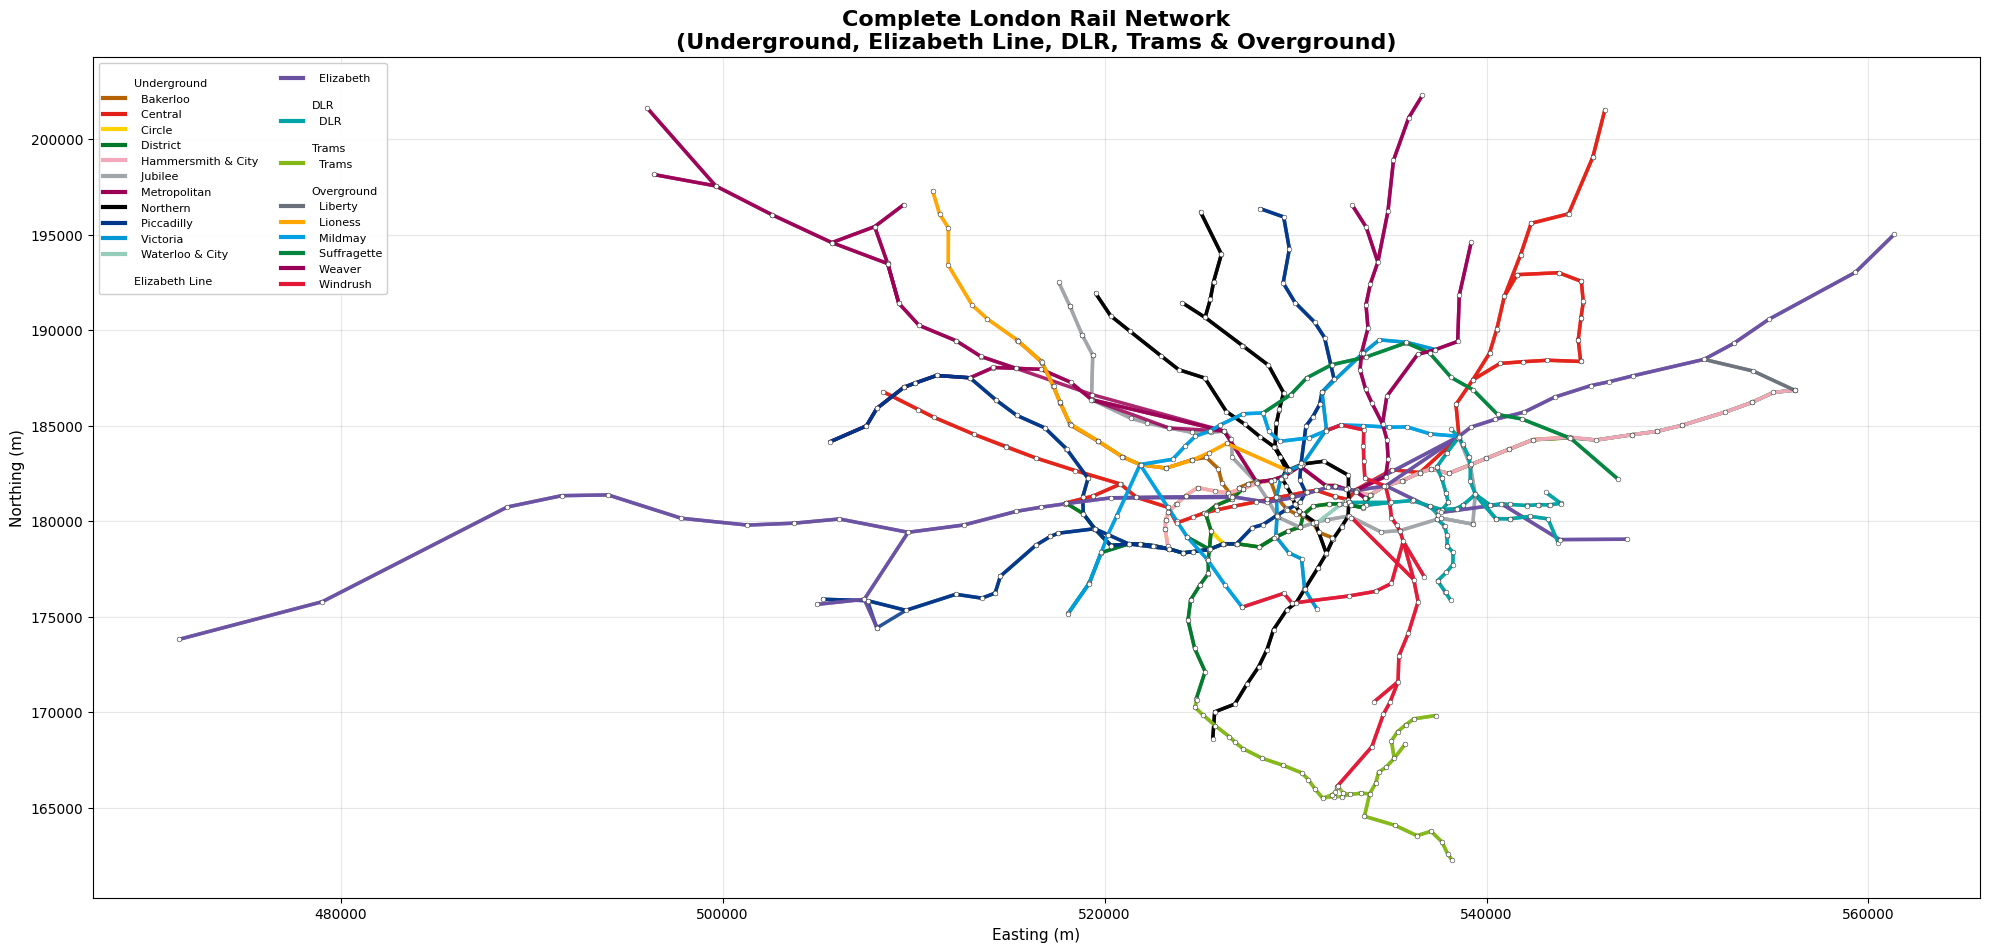

In [6]:
fig, ax = plt.subplots(figsize=(20, 22))

# Draw all lines with their colors
for line_code, edges in all_edges.items():
    color, name = ALL_LINES[line_code]
    plot_line(ax, edges, stop_coords, color, linewidth=2.5, alpha=0.85)

# Draw stations
network_stations = get_network_stations(all_edges, stop_coords)
for station in network_stations:
    ax.scatter(stop_coords[station]['Easting'], stop_coords[station]['Northing'],
              c='white', s=12, edgecolors='black', linewidth=0.3, zorder=10)

ax.set_xlabel('Easting (m)', fontsize=11)
ax.set_ylabel('Northing (m)', fontsize=11)
ax.set_title('Complete London Rail Network\n(Underground, Elizabeth Line, DLR, Trams & Overground)', 
             fontsize=16, fontweight='bold')
ax.set_aspect('equal')
ax.grid(True, alpha=0.3)

# Create grouped legend
legend_elements = []
for category, codes in SERVICE_CATEGORIES.items():
    # Category header
    legend_elements.append(Line2D([0], [0], color='none', label=f'\n{category}'))
    for code in codes:
        if code in all_edges:
            color, name = ALL_LINES[code]
            legend_elements.append(Line2D([0], [0], color=color, linewidth=3, label=f'  {name}'))

ax.legend(handles=legend_elements, loc='upper left', fontsize=8, ncol=2, framealpha=0.95)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'aggregated_network_complete.png', dpi=150, bbox_inches='tight')
plt.show()

## Network with Geographic Coverage Overlay

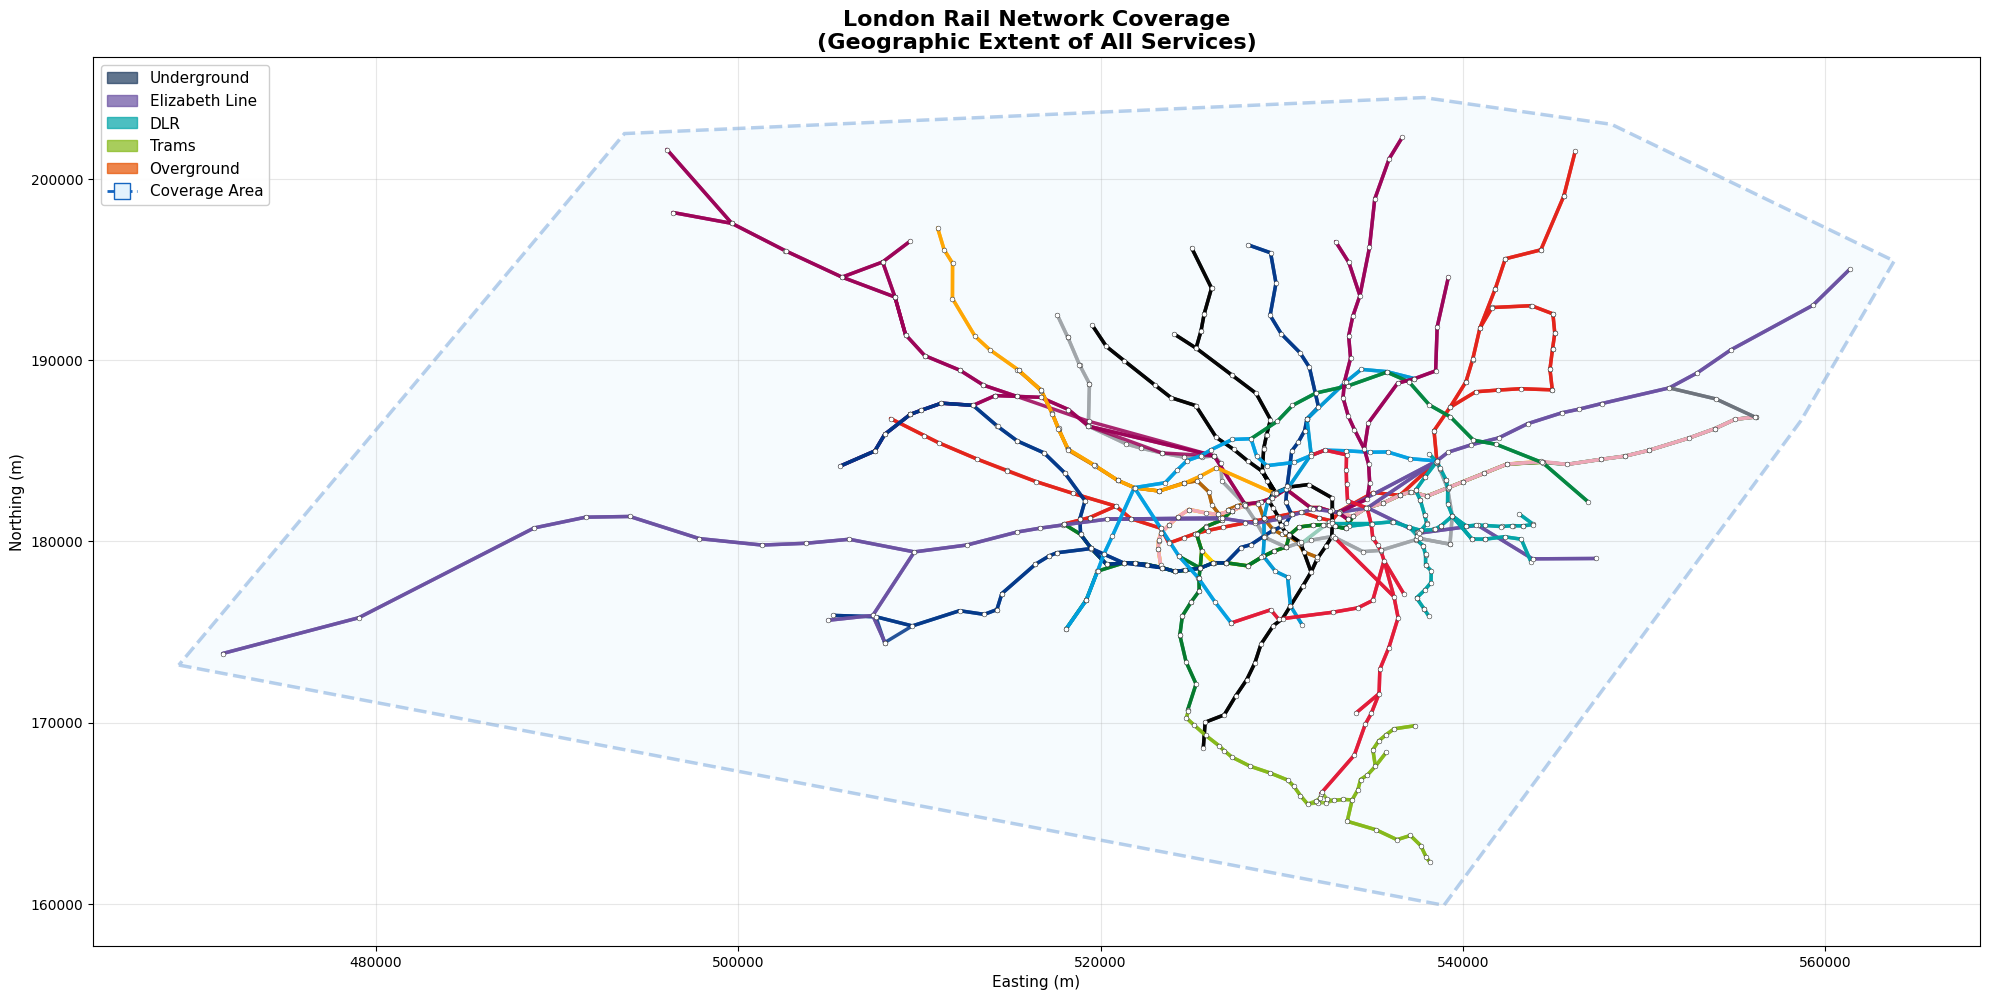

In [7]:
fig, ax = plt.subplots(figsize=(20, 22))

# Get all network stations
network_stations = get_network_stations(all_edges, stop_coords)

# Create and draw coverage area
hull_points = create_coverage_hull(network_stations, stop_coords, buffer_m=2500)
coverage_polygon = Polygon(hull_points, closed=True, 
                           facecolor='#E3F2FD', edgecolor='#1565C0', 
                           alpha=0.3, linewidth=2.5, linestyle='--',
                           zorder=1)
ax.add_patch(coverage_polygon)

# Draw all lines
for line_code, edges in all_edges.items():
    color, name = ALL_LINES[line_code]
    plot_line(ax, edges, stop_coords, color, linewidth=2.5, alpha=0.85)

# Draw stations
for station in network_stations:
    ax.scatter(stop_coords[station]['Easting'], stop_coords[station]['Northing'],
              c='white', s=12, edgecolors='black', linewidth=0.3, zorder=10)

ax.set_xlabel('Easting (m)', fontsize=11)
ax.set_ylabel('Northing (m)', fontsize=11)
ax.set_title('London Rail Network Coverage\n(Geographic Extent of All Services)', 
             fontsize=16, fontweight='bold')
ax.set_aspect('equal')
ax.grid(True, alpha=0.3)

# Simplified legend by category
legend_elements = []
for category, color in CATEGORY_COLORS.items():
    codes = SERVICE_CATEGORIES[category]
    if any(code in all_edges for code in codes):
        legend_elements.append(Patch(facecolor=color, edgecolor=color, alpha=0.7, label=category))

legend_elements.append(Line2D([0], [0], color='#1565C0', linewidth=2, linestyle='--',
                              marker='s', markersize=12, markerfacecolor='#E3F2FD',
                              markeredgecolor='#1565C0', label='Coverage Area'))

ax.legend(handles=legend_elements, loc='upper left', fontsize=11, framealpha=0.95)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'aggregated_network_coverage.png', dpi=150, bbox_inches='tight')
plt.show()

## Network by Service Type

Color-coded by service category rather than individual lines.

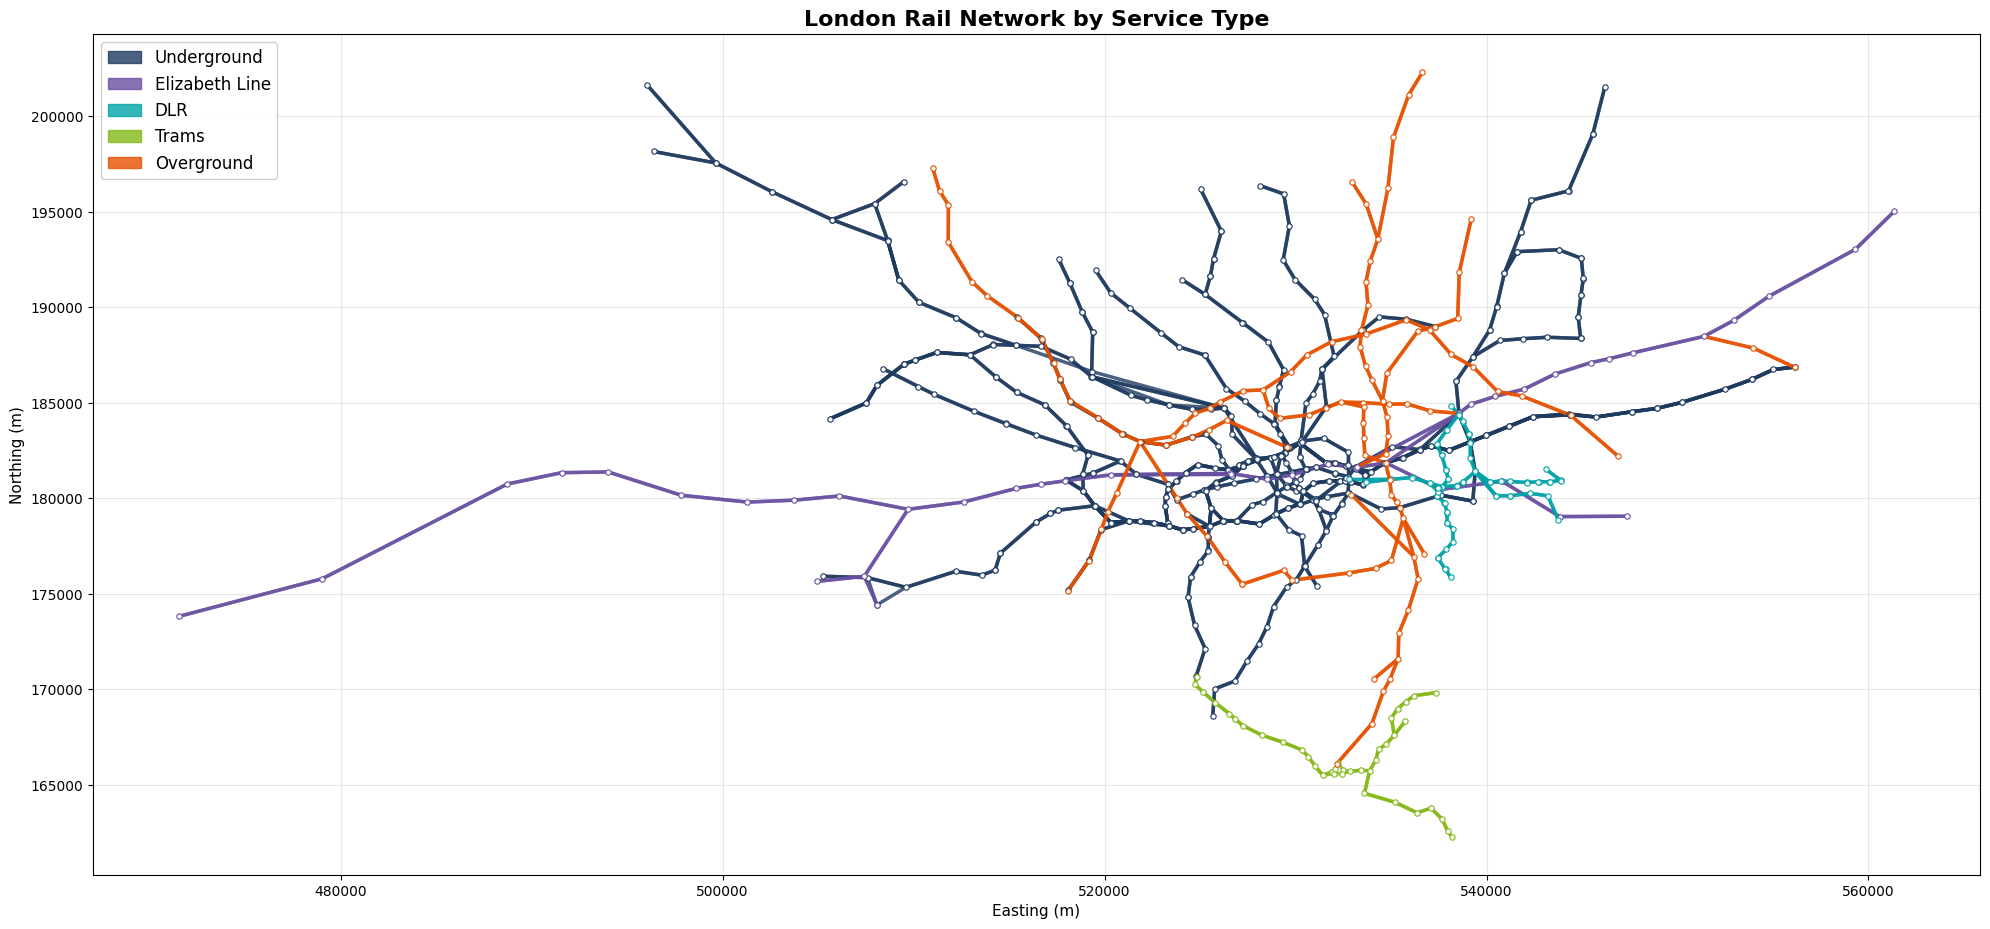

In [8]:
fig, ax = plt.subplots(figsize=(20, 22))

# Draw lines colored by category
for category, codes in SERVICE_CATEGORIES.items():
    color = CATEGORY_COLORS[category]
    for line_code in codes:
        if line_code in all_edges:
            plot_line(ax, all_edges[line_code], stop_coords, color, linewidth=2.5, alpha=0.8)

# Draw stations colored by their primary service
station_category = {}
for category, codes in SERVICE_CATEGORIES.items():
    for code in codes:
        if code in all_edges:
            edges = all_edges[code]
            for station in edges['From_StopPointRef'].tolist() + edges['To_StopPointRef'].tolist():
                if station not in station_category:
                    station_category[station] = category

for station, category in station_category.items():
    if station in stop_coords:
        ax.scatter(stop_coords[station]['Easting'], stop_coords[station]['Northing'],
                  c='white', s=15, edgecolors=CATEGORY_COLORS[category], linewidth=0.8, zorder=10)

ax.set_xlabel('Easting (m)', fontsize=11)
ax.set_ylabel('Northing (m)', fontsize=11)
ax.set_title('London Rail Network by Service Type', fontsize=16, fontweight='bold')
ax.set_aspect('equal')
ax.grid(True, alpha=0.3)

# Legend by category
legend_elements = [Patch(facecolor=color, edgecolor=color, alpha=0.8, label=category)
                   for category, color in CATEGORY_COLORS.items()
                   if any(code in all_edges for code in SERVICE_CATEGORIES[category])]

ax.legend(handles=legend_elements, loc='upper left', fontsize=12, framealpha=0.95)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'aggregated_network_by_service.png', dpi=150, bbox_inches='tight')
plt.show()

## Service Comparison (Side-by-Side)

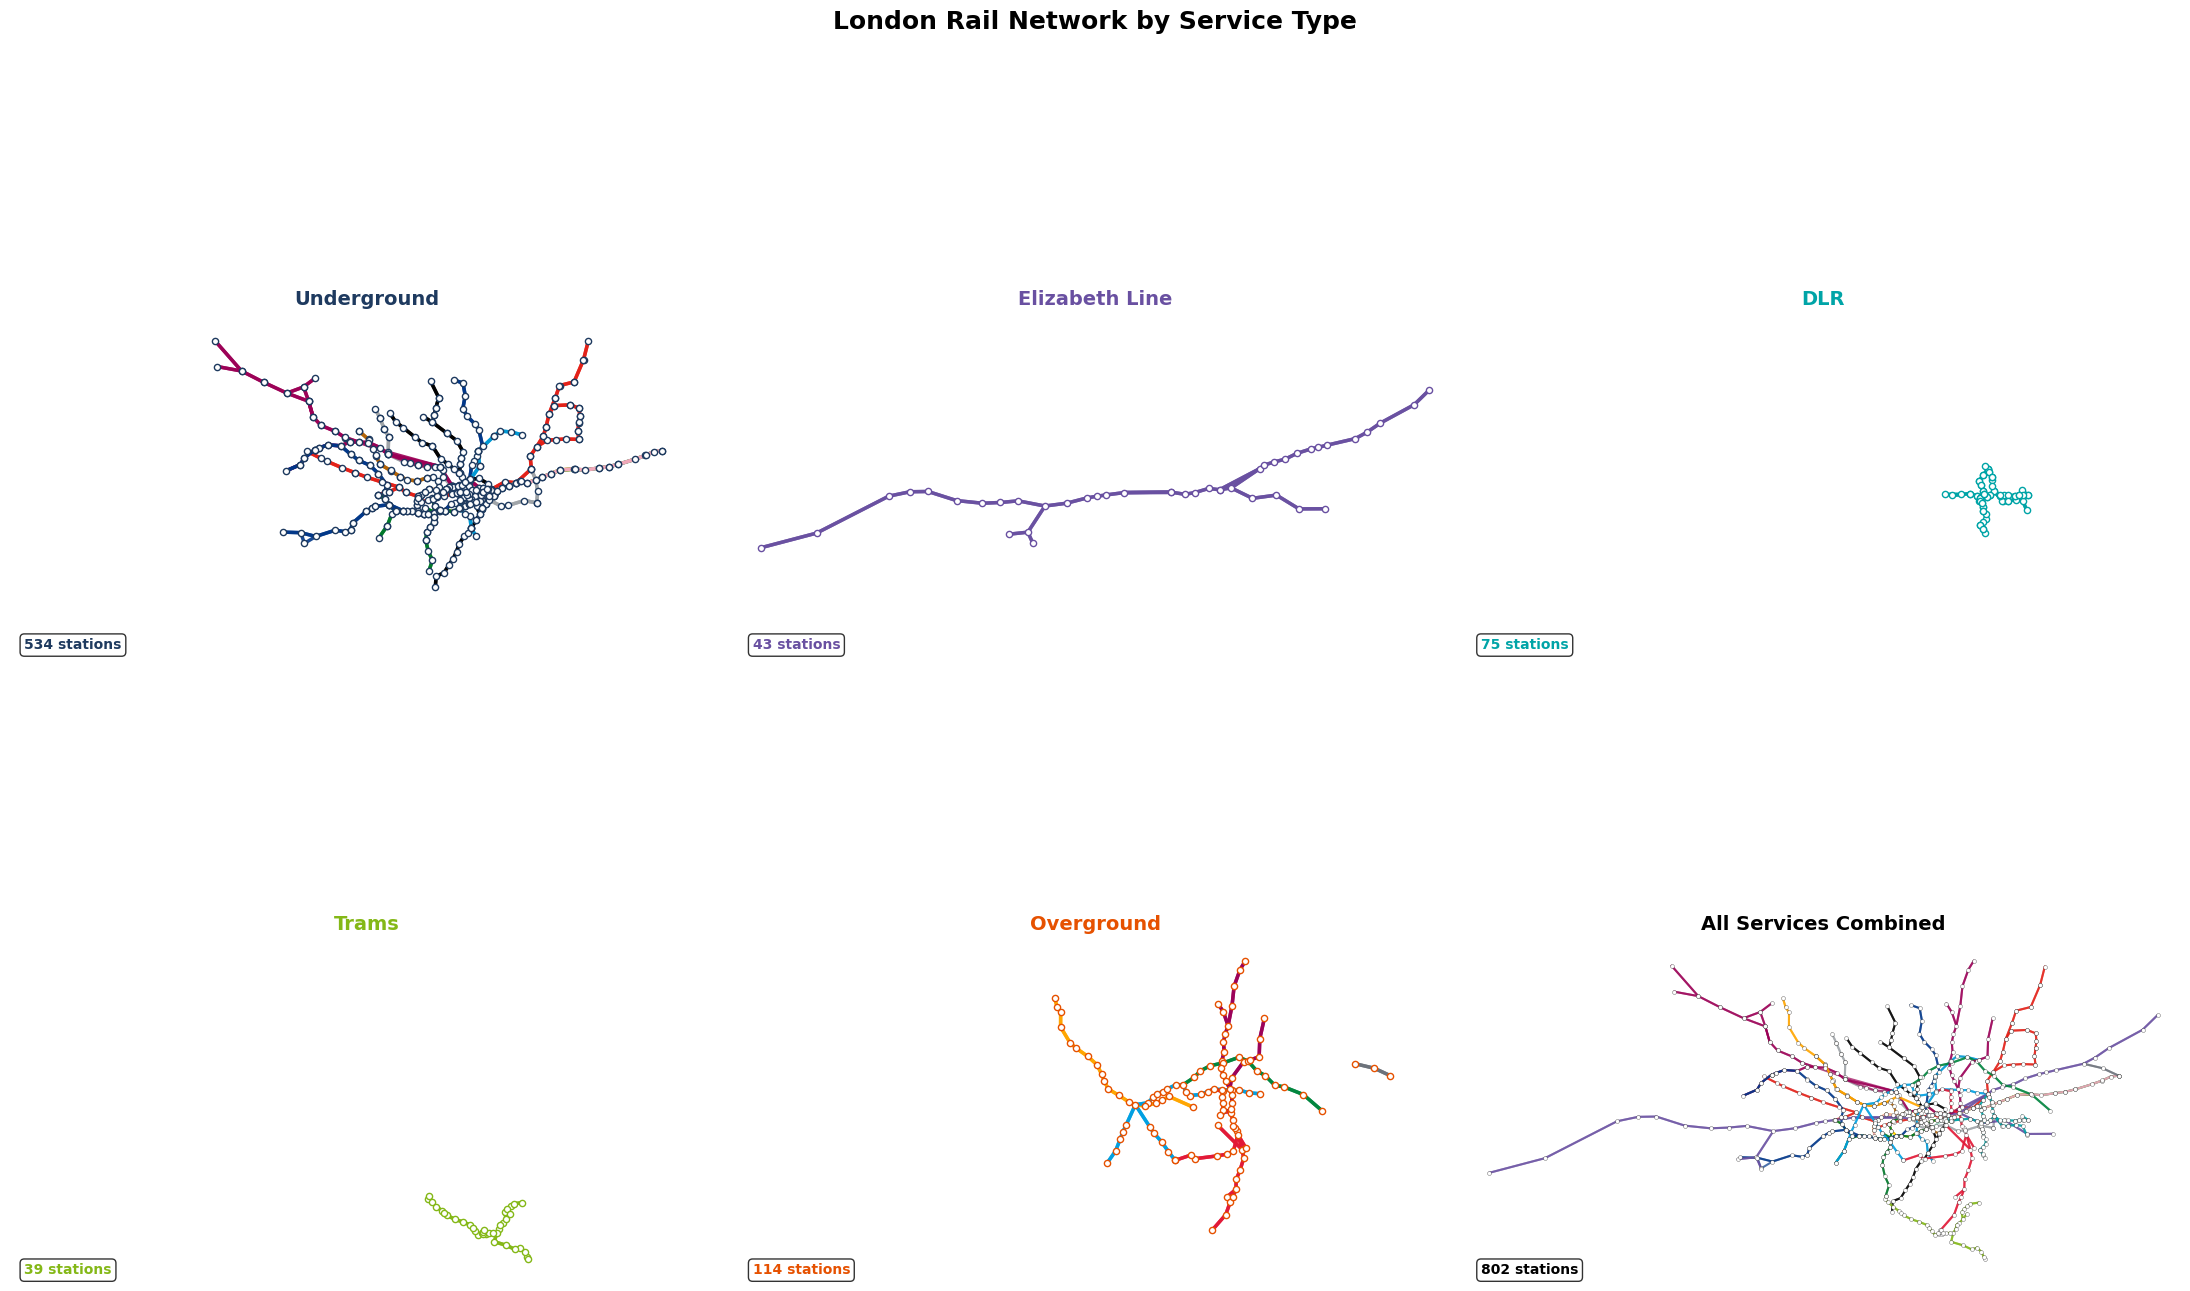

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(22, 16))
axes = axes.flatten()

# Get global bounds for consistent scaling
all_stations = get_network_stations(all_edges, stop_coords)
all_x = [stop_coords[s]['Easting'] for s in all_stations]
all_y = [stop_coords[s]['Northing'] for s in all_stations]
x_min, x_max = min(all_x), max(all_x)
y_min, y_max = min(all_y), max(all_y)
margin = 3000

categories = list(SERVICE_CATEGORIES.keys())

for idx, category in enumerate(categories):
    ax = axes[idx]
    codes = SERVICE_CATEGORIES[category]
    cat_color = CATEGORY_COLORS[category]
    
    # Draw lines for this category
    cat_edges = {code: all_edges[code] for code in codes if code in all_edges}
    
    if not cat_edges:
        ax.text(0.5, 0.5, f'No data for {category}', 
                ha='center', va='center', transform=ax.transAxes, fontsize=12)
        ax.axis('off')
        continue
    
    for line_code, edges in cat_edges.items():
        color, name = ALL_LINES[line_code]
        plot_line(ax, edges, stop_coords, color, linewidth=2.5, alpha=0.9)
    
    # Draw stations
    cat_stations = get_network_stations(cat_edges, stop_coords)
    for station in cat_stations:
        ax.scatter(stop_coords[station]['Easting'], stop_coords[station]['Northing'],
                  c='white', s=20, edgecolors=cat_color, linewidth=1, zorder=10)
    
    ax.set_xlim(x_min - margin, x_max + margin)
    ax.set_ylim(y_min - margin, y_max + margin)
    ax.set_title(category, fontsize=14, color=cat_color, fontweight='bold')
    ax.set_aspect('equal')
    ax.axis('off')
    
    # Add station count
    ax.text(0.02, 0.02, f'{len(cat_stations)} stations', transform=ax.transAxes,
            fontsize=10, color=cat_color, fontweight='bold',
            bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

# Use last subplot for combined view
ax = axes[5]
for line_code, edges in all_edges.items():
    color, name = ALL_LINES[line_code]
    plot_line(ax, edges, stop_coords, color, linewidth=1.5, alpha=0.7)

for station in all_stations:
    ax.scatter(stop_coords[station]['Easting'], stop_coords[station]['Northing'],
              c='white', s=8, edgecolors='black', linewidth=0.2, zorder=10)

ax.set_xlim(x_min - margin, x_max + margin)
ax.set_ylim(y_min - margin, y_max + margin)
ax.set_title('All Services Combined', fontsize=14, fontweight='bold')
ax.set_aspect('equal')
ax.axis('off')
ax.text(0.02, 0.02, f'{len(all_stations)} stations', transform=ax.transAxes,
        fontsize=10, fontweight='bold',
        bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

plt.suptitle('London Rail Network by Service Type', fontsize=18, fontweight='bold', y=0.98)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'aggregated_network_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

## Network with Zone Coverage

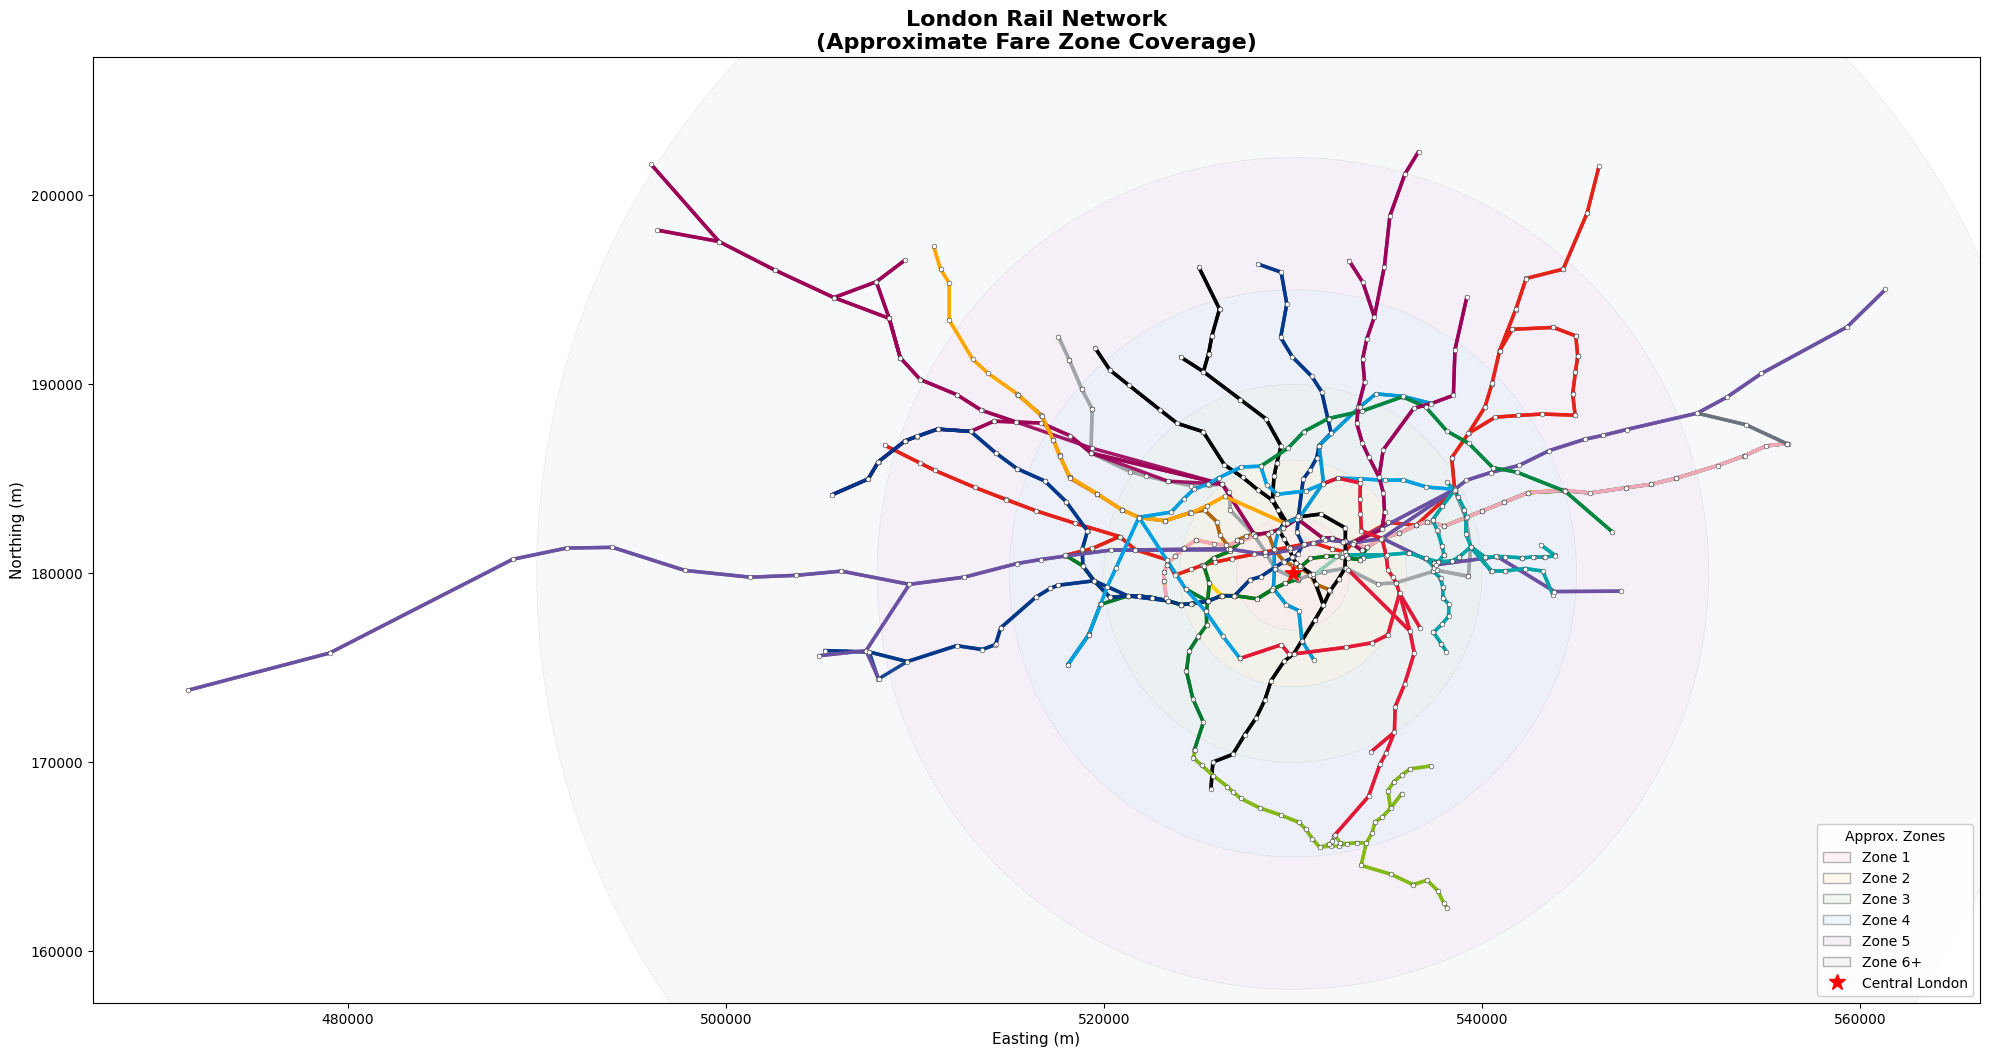

In [10]:
fig, ax = plt.subplots(figsize=(20, 22))

# Central London (near Charing Cross)
central_x, central_y = 530000, 180000

# Draw zone circles
zone_radii = [3000, 6000, 10000, 15000, 22000, 40000]
zone_colors = ['#FFEBEE', '#FFF3E0', '#E8F5E9', '#E3F2FD', '#F3E5F5', '#ECEFF1']
zone_labels = ['Zone 1', 'Zone 2', 'Zone 3', 'Zone 4', 'Zone 5', 'Zone 6+']

for radius, color in zip(reversed(zone_radii), reversed(zone_colors)):
    circle = Circle((central_x, central_y), radius, 
                    facecolor=color, edgecolor='gray', 
                    alpha=0.4, linewidth=0.5, linestyle=':', zorder=1)
    ax.add_patch(circle)

# Draw all lines
for line_code, edges in all_edges.items():
    color, name = ALL_LINES[line_code]
    plot_line(ax, edges, stop_coords, color, linewidth=2.5, alpha=0.9)

# Draw stations
network_stations = get_network_stations(all_edges, stop_coords)
for station in network_stations:
    ax.scatter(stop_coords[station]['Easting'], stop_coords[station]['Northing'],
              c='white', s=12, edgecolors='black', linewidth=0.3, zorder=10)

# Mark central point
ax.scatter(central_x, central_y, c='red', s=150, marker='*', zorder=20)

ax.set_xlabel('Easting (m)', fontsize=11)
ax.set_ylabel('Northing (m)', fontsize=11)
ax.set_title('London Rail Network\n(Approximate Fare Zone Coverage)', fontsize=16, fontweight='bold')
ax.set_aspect('equal')

# Set limits
all_x = [stop_coords[s]['Easting'] for s in network_stations]
all_y = [stop_coords[s]['Northing'] for s in network_stations]
margin = 5000
ax.set_xlim(min(all_x) - margin, max(all_x) + margin)
ax.set_ylim(min(all_y) - margin, max(all_y) + margin)

# Zone legend
zone_elements = [Patch(facecolor=color, edgecolor='gray', alpha=0.6, label=label)
                 for color, label in zip(zone_colors, zone_labels)]
zone_elements.append(Line2D([0], [0], marker='*', color='red', markersize=12, linestyle='', label='Central London'))
ax.legend(handles=zone_elements, loc='lower right', fontsize=10, framealpha=0.95, title='Approx. Zones')

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'aggregated_network_zones.png', dpi=150, bbox_inches='tight')
plt.show()

## Complete Network Statistics

In [11]:
print("=" * 80)
print("COMPLETE LONDON RAIL NETWORK STATISTICS")
print("=" * 80)

total_stations = len(get_network_stations(all_edges, stop_coords))
total_edges = sum(len(edges) for edges in all_edges.values())
total_lines = len(all_edges)

print(f"\nOVERALL NETWORK:")
print(f"  Total Stations: {total_stations}")
print(f"  Total Connections: {total_edges}")
print(f"  Total Lines: {total_lines}")

# Network extent
network_stations = get_network_stations(all_edges, stop_coords)
all_x = [stop_coords[s]['Easting'] for s in network_stations]
all_y = [stop_coords[s]['Northing'] for s in network_stations]

width_km = (max(all_x) - min(all_x)) / 1000
height_km = (max(all_y) - min(all_y)) / 1000

print(f"\nNETWORK EXTENT:")
print(f"  Width (E-W): {width_km:.1f} km")
print(f"  Height (N-S): {height_km:.1f} km")

# Coverage area
points = np.array([[stop_coords[s]['Easting'], stop_coords[s]['Northing']] 
                   for s in network_stations])
hull = ConvexHull(points)
coverage_km2 = hull.volume / 1e6
print(f"  Coverage Area: {coverage_km2:.1f} km²")

# By service category
print("\n" + "=" * 80)
print("BY SERVICE CATEGORY:")
print("=" * 80)

for category, codes in SERVICE_CATEGORIES.items():
    cat_edges = {code: all_edges[code] for code in codes if code in all_edges}
    if not cat_edges:
        continue
    
    cat_stations = len(get_network_stations(cat_edges, stop_coords))
    cat_connections = sum(len(e) for e in cat_edges.values())
    
    # Calculate total length
    total_length = 0
    for edges in cat_edges.values():
        for _, edge in edges.iterrows():
            from_stop = edge['From_StopPointRef']
            to_stop = edge['To_StopPointRef']
            if from_stop in stop_coords and to_stop in stop_coords:
                dx = stop_coords[to_stop]['Easting'] - stop_coords[from_stop]['Easting']
                dy = stop_coords[to_stop]['Northing'] - stop_coords[from_stop]['Northing']
                total_length += np.sqrt(dx**2 + dy**2)
    
    print(f"\n{category}:")
    print(f"  Lines: {len(cat_edges)}")
    print(f"  Stations: {cat_stations}")
    print(f"  Connections: {cat_connections}")
    print(f"  Approx. Length: {total_length/1000:.1f} km")

# Detailed by line
print("\n" + "=" * 80)
print("DETAILED BY LINE:")
print("=" * 80)
print(f"{'Line':<25} {'Stations':>10} {'Connections':>12} {'Length (km)':>12}")
print("-" * 60)

for category, codes in SERVICE_CATEGORIES.items():
    print(f"\n{category}:")
    for line_code in codes:
        if line_code not in all_edges:
            continue
        
        edges = all_edges[line_code]
        color, name = ALL_LINES[line_code]
        line_stations = set(edges['From_StopPointRef'].tolist() + edges['To_StopPointRef'].tolist())
        valid_stations = [s for s in line_stations if s in stop_coords]
        
        total_length = 0
        for _, edge in edges.iterrows():
            from_stop = edge['From_StopPointRef']
            to_stop = edge['To_StopPointRef']
            if from_stop in stop_coords and to_stop in stop_coords:
                dx = stop_coords[to_stop]['Easting'] - stop_coords[from_stop]['Easting']
                dy = stop_coords[to_stop]['Northing'] - stop_coords[from_stop]['Northing']
                total_length += np.sqrt(dx**2 + dy**2)
        
        print(f"  {name:<23} {len(valid_stations):>10} {len(edges):>12} {total_length/1000:>12.1f}")

print("\n" + "=" * 80)

COMPLETE LONDON RAIL NETWORK STATISTICS

OVERALL NETWORK:
  Total Stations: 802
  Total Connections: 1318
  Total Lines: 20

NETWORK EXTENT:
  Width (E-W): 89.8 km
  Height (N-S): 40.0 km
  Coverage Area: 2404.7 km²

BY SERVICE CATEGORY:

Underground:
  Lines: 11
  Stations: 534
  Connections: 842
  Approx. Length: 1017.9 km

Elizabeth Line:
  Lines: 1
  Stations: 43
  Connections: 84
  Approx. Length: 259.3 km

DLR:
  Lines: 1
  Stations: 75
  Connections: 97
  Approx. Length: 73.6 km

Trams:
  Lines: 1
  Stations: 39
  Connections: 71
  Approx. Length: 50.9 km

Overground:
  Lines: 6
  Stations: 114
  Connections: 224
  Approx. Length: 340.4 km

DETAILED BY LINE:
Line                        Stations  Connections  Length (km)
------------------------------------------------------------

Underground:
  Bakerloo                        43           48         45.1
  Central                         79           98        142.5
  Circle                         113          120         99.4